# Podstawy AI – Logika rozmyta: decyzje i sterownik

Plan:
1. Wybór uczelni – czy operator „i” zmienia decyzję?
2. Sterownik pralki – od dwóch reguł do pełnego sterownika
3. Podsumowanie

**Jak pracujemy:**
- **TODO** w kodzie – tu piszesz kod lub zmieniasz liczby.
- **Testy** – komórka, którą uruchamiasz bez zmian. Wypisze `OK` albo `BŁĄD` z przypadkiem, który nie działa.
- **Pytanie** – odpowiadasz 2–3 zdaniami w komórce „Twoja odpowiedź”.

Kto zrobił wybór uczelni na poprzednich zajęciach, zaczyna od razu od części 2.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce

# ---- Gotowe funkcje z poprzednich zajęć ---------------------------------
def gamma(x, a, b):
    return np.clip((np.asarray(x, float) - a) / (b - a), 0, 1)


def L(x, a, b):
    return np.clip((b - np.asarray(x, float)) / (b - a), 0, 1)

def t(x, a, b, c):
    x = np.asarray(x, float)
    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0, 1)

def T_min(a, b):     return np.minimum(a, b)
def T_iloczyn(a, b): return np.asarray(a, float) * b
def T_luk(a, b):     return np.maximum(0, np.asarray(a, float) + b - 1)
def S_max(a, b):     return np.maximum(a, b)


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6, equal_nan=True)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"BŁĄD  {nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"OK    {nazwa}" if bledy == 0 else f"      {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Wybór uczelni – czy operator „i” zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**.

Dane są liczbami, a kryteria są rozmyte. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów, a potem łączymy cztery kryteria operatorem „i” (t-normą).

### 1.1 Od danych do stopni

In [28]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

def tabela_stopni(kryteria):
    stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
    print("      ranking  blisko  wymiana  praca")
    for w, s in stopnie.items():
        print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))
    return stopnie

stopnie = tabela_stopni(kryteria)

      ranking  blisko  wymiana  praca
w1     0.60    0.60    0.60    0.60
w2     1.00    0.45    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.77    0.08    0.83


### 1.2 Cztery sposoby rozumienia „i”

`reduce(T, [k1, k2, k3, k4])` liczy „k1 i k2 i k3 i k4” wybraną t-normą. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [29]:
OPERATORY = {
    "minimum":            lambda s: float(reduce(T_min, s)),
    "iloczyn":            lambda s: float(reduce(T_iloczyn, s)),
    "Łukasiewicz":        lambda s: float(reduce(T_luk, s)),
    "średnia (to NIE i)": lambda s: float(np.mean(s)),
}

def ranking(stopnie):
    print(f"{'operator':<20}" + "".join(f"{w:>7}" for w in wydzialy) + "   kolejność")
    for nazwa, op in OPERATORY.items():
        oceny = {w: op(s) for w, s in stopnie.items()}
        kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
        print(f"{nazwa:<20}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

ranking(stopnie)

operator                 w1     w2     w3     w4   kolejność
minimum                0.60   0.45   0.14   0.08   w1 > w2 > w3 > w4
iloczyn                0.13   0.45   0.01   0.04   w2 > w1 > w4 > w3
Łukasiewicz            0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
średnia (to NIE i)     0.60   0.86   0.44   0.62   w2 > w4 > w1 > w3


**Pytanie 1a.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

**Pytanie 1b.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam stopień 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?


*Twoja odpowiedź:*

1a. Przy minimum wygrywa w1, a przy iloczynie w2. Dzieje się tak, bo minimum bierze pod uwagę tylko najsłabszy wynik, a iloczyn uwzględnia wszystkie kryteria.

1b. Średnia nie jest „i”, bo dobre wyniki mogą przykryć słaby wynik w jednym kryterium. W4 ma słabą wymianę zagraniczną, ale dobrze wypada w pozostałych rzeczach. Średnia ma sens, jeśli jesteśmy gotowi iść na kompromisy.

### 1.3 Ty jesteś kandydatem

Kryteria w `kryteria()` wpisał ktoś inny. Teraz zdefiniuj je po swojemu.

1. Dla kandydata, dla którego odległość jest **bardzo** ważna, „blisko domu” znaczy co innego. Zmień to kryterium na `L(odleglosc, 10, 50)` i uruchom komórkę.
2. Potem zmień **jedno dowolne** kryterium tak, jak sam je rozumiesz.

In [30]:
def moje_kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),
        L(odleglosc, 10, 50),    # TODO: zmień na L(odleglosc, 10, 50)
        gamma(wymiana, 5, 30),
        gamma(praca, 60, 90),
    ]

moje_stopnie = tabela_stopni(moje_kryteria)
print()
ranking(moje_stopnie)

      ranking  blisko  wymiana  praca
w1     0.60    0.00    0.60    0.60
w2     1.00    0.00    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.00    0.08    0.83

operator                 w1     w2     w3     w4   kolejność
minimum                0.00   0.00   0.14   0.00   w3 > w1 > w2 > w4
iloczyn                0.00   0.00   0.01   0.00   w3 > w1 > w2 > w4
Łukasiewicz            0.00   0.00   0.00   0.00   w1 > w2 > w3 > w4
średnia (to NIE i)     0.45   0.75   0.44   0.43   w2 > w1 > w3 > w4


**Pytanie 1c.** Kto wygrywa po zmianie „blisko domu” na `L(odleglosc, 10, 50)`? Co bardziej zmienia decyzję: wybór operatora czy definicja kryterium?

**Pytanie 1d.** Który operator najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię? Uzasadnij.

*Twoja odpowiedź:*

1c. Po zmianie kryterium odległości przy minimum i iloczynie wygrywa w3. W3 jest jedynym wydziałem, który ma niezerowy stopień bliskości według tej ostrzejszej definicji. W Łukasiewiczu cały ranking jest wyzerowany. Średnia wskazuje w2. Definicja kryterium może zmienić decyzję równie mocno, a nawet mocniej niż operator.

1d. W tym przypadku wybrałabym średnią. Mogę przymknąć oko na słabszy wynik jednego z kryteriów, jeśli ogół jest dobry.

---
## Część 2. Sterownik pralki

Budujemy **sterownik**: program, który z reguł JEŚLI–TO wylicza czas prania. Działa w pięciu krokach:

| krok | co się dzieje |
|---|---|
| 1. rozmycie | liczby (np. 55%, 4 kg) zamieniamy na stopnie: „brud duży w stopniu 0,38” |
| 2. siła reguł | ile prawdy jest w części JEŚLI każdej reguły (t-norma) |
| 3. implikacja | zbiór wyjściowy przycinamy (min) albo skalujemy (iloczyn) siłą reguły |
| 4. łączenie | wnioski wszystkich reguł łączymy w jeden kształt (maksimum) |
| 5. wyostrzanie | z kształtu robimy jedną liczbę minut |

Zaczniemy od pralki z dwiema regułami, znajdziemy jej wady na **mapie sterownika** i zbudujemy pełną wersję.

### 2.1 Zbiory rozmyte pralki

Każda zmienna ma swoje zbiory, zapisane jako słownik `{nazwa: funkcja}`. Na start pralka zna tylko kilka z nich.

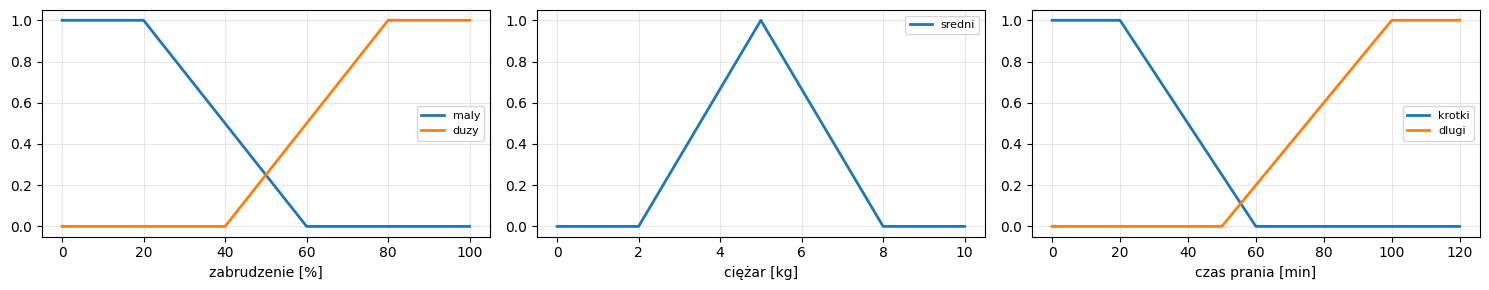

In [31]:
BRUD = {                                   # zabrudzenie [%], 0–100
    "maly": lambda x: L(x, 20, 60),
    "duzy": lambda x: gamma(x, 40, 80),
}
CIEZAR = {                                 # ciężar prania [kg], 0–10
    "sredni": lambda x: t(x, 2, 5, 8),
}
CZAS = {                                   # czas prania [min], 0–120
    "krotki": lambda x: L(x, 20, 60),
    "dlugi":  lambda x: gamma(x, 50, 100),
}

def rysuj_zbiory(BRUD, CIEZAR, CZAS):
    fig, osie = plt.subplots(1, 3, figsize=(15, 3))
    for os_, (nazwa, zbiory, zakres) in zip(osie, [("zabrudzenie [%]", BRUD, 100),
                                                   ("ciężar [kg]", CIEZAR, 10),
                                                   ("czas prania [min]", CZAS, 120)]):
        xs = np.linspace(0, zakres, 501)
        for n, f in zbiory.items():
            os_.plot(xs, f(xs), lw=2, label=n)
        os_.set_xlabel(nazwa); os_.legend(fontsize=8); os_.grid(alpha=.3)
    plt.tight_layout(); plt.show()

rysuj_zbiory(BRUD, CIEZAR, CZAS)

**Pytanie 2a.** Spójrz na wykres ciężaru. Jaki stopień ma „średni” ciężar dla 1 kg i dla 9 kg? Co to może oznaczać dla pralki?

*Twoja odpowiedź:* Zarówno dla 1 kg, jak i dla 9 kg stopień przynależności do zbioru ,,średni” wynosi 0. To znaczy, że według naszego programu taki ciężar nie jest średni, a pralka nie będzie postępowała z tym praniem w sposób, w który postępuje z praniem o tego typu wadze.

### 2.2 Środek ciężkości

Ostatni krok, **wyostrzanie**, zamienia kształt na jedną liczbę. Kształt to dwie tablice: `x` – możliwe czasy prania, `mu` – wysokość kształtu nad każdym czasem. Środek ciężkości to średnia ważona czasów, a wagą jest `mu`:

$$x^* = \frac{x_1 \mu_1 + x_2 \mu_2 + \dots}{\mu_1 + \mu_2 + \dots}$$

Przykład: x = 0, 10, 20, 30 i mu = 0; 1; 0; 0,5 daje (10 · 1 + 30 · 0,5) / (1 + 0,5) = 25 / 1,5 ≈ 16,67.

Zaimplementuj tę funkcję. Jeśli wszystkie `mu` są zerami (żadna reguła nie zadziałała), zwróć `np.nan`.

In [32]:
def srodek_ciezkosci(x, mu):
    x, mu = np.asarray(x, float), np.asarray(mu, float)
    # TODO
    suma = np.sum(mu)

    if suma == 0:
      return np.nan

    return np.sum(x * mu) / suma

In [33]:
# Testy
xs = np.array([0.0, 10.0, 20.0, 30.0])
sprawdz("srodek_ciezkosci", srodek_ciezkosci, [((xs, np.array([0, 1, 1, 0])), 15),
                                             ((xs, np.array([0, 0, 0, 1])), 30),
                                             ((xs, np.array([1, 0, 0, 1])), 15),
                                             ((xs, np.array([0, 1, 0, 0.5])), 50 / 3),
                                             ((xs, np.array([0, 0, 0, 0])), np.nan)])

OK    srodek_ciezkosci


### 2.3 Sterownik z dwiema regułami i mapa sterownika

Reguły zapisujemy jako słownik `{(brud, ciężar): czas}`. `None` znaczy „dowolny ciężar”:

- **R1:** JEŚLI brud **duży** I ciężar **średni**, TO czas **długi**
- **R2:** JEŚLI brud **mały**, TO czas **krótki**

Funkcja `sterownik` wykonuje pięć kroków dla dowolnego zestawu reguł. Nie musisz jej zmieniać – przeczytaj komentarze.

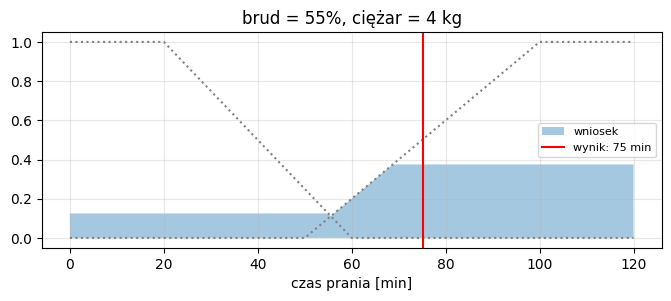

55%, 4 kg -> 75 min


In [34]:
czas = np.linspace(0, 120, 1201)

def srodek_maksimum(x, mu):
    """Inna metoda wyostrzania: środek przedziału, w którym kształt jest najwyższy."""
    if np.max(mu) == 0:
        return np.nan
    return x[np.isclose(mu, np.max(mu))].mean()

def sterownik(brud, ciezar, reguly, T=T_min, implikacja="min", wyostrzanie=None, pokaz=False):
    wyostrzanie = wyostrzanie or srodek_ciezkosci
    # 1. rozmycie wejść
    st_brud = {n: float(f(brud)) for n, f in BRUD.items()}
    st_ciezar = {n: float(f(ciezar)) for n, f in CIEZAR.items()}
    wynik = np.zeros_like(czas)
    for (b, c), wyjscie in reguly.items():
        # 2. siła reguły (None = dowolny ciężar)
        sila = st_brud[b] if c is None else float(T(st_brud[b], st_ciezar[c]))
        # 3. implikacja: "min" przycina zbiór wyjściowy, "iloczyn" go skaluje
        zbior = CZAS[wyjscie](czas)
        wniosek = np.minimum(sila, zbior) if implikacja == "min" else sila * zbior
        # 4. łączenie wniosków
        wynik = S_max(wynik, wniosek)
    # 5. wyostrzanie
    x_star = wyostrzanie(czas, wynik)
    if pokaz:
        plt.figure(figsize=(8, 2.8))
        for n, f in CZAS.items():
            plt.plot(czas, f(czas), ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        if not np.isnan(x_star):
            plt.axvline(x_star, c="r", label=f"wynik: {x_star:.0f} min")
        plt.title(f"brud = {brud}%, ciężar = {ciezar} kg"); plt.xlabel("czas prania [min]")
        plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return x_star


REGULY_2 = {
    ("duzy", "sredni"): "dlugi",    # R1
    ("maly", None):     "krotki",   # R2
}

print(f"55%, 4 kg -> {sterownik(55, 4, REGULY_2, pokaz=True):.0f} min")

Sprawdzanie sterownika punkt po punkcie jest żmudne. **Mapa sterownika** liczy wynik dla wszystkich kombinacji zabrudzenia i ciężaru naraz. Białe pola to miejsca, gdzie **żadna reguła nie działa**.

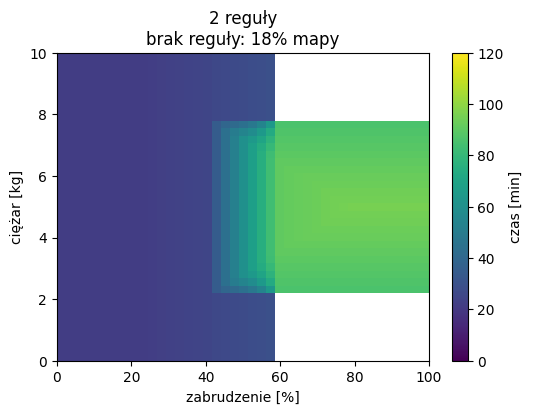

In [35]:
def mapa(reguly, ax=None, tytul="", **ustawienia):
    brudy = np.linspace(0, 100, 41)
    ciezary = np.linspace(0, 10, 41)
    Z = np.array([[sterownik(b, c, reguly, **ustawienia) for b in brudy] for c in ciezary])
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    im = ax.imshow(Z, origin="lower", aspect="auto", extent=[0, 100, 0, 10], cmap="viridis", vmin=0, vmax=120)
    ax.set_xlabel("zabrudzenie [%]"); ax.set_ylabel("ciężar [kg]")
    ax.set_title(f"{tytul}\nbrak reguły: {np.isnan(Z).mean() * 100:.0f}% mapy")
    plt.colorbar(im, ax=ax, label="czas [min]")
    return Z

Z_2 = mapa(REGULY_2, tytul="2 reguły")
plt.show()

**Pytanie 2b.** Gdzie na mapie są białe pola? Opisz słowami, jakie to prania. Co zrobi prawdziwa pralka, gdy sterownik nie zwróci żadnej liczby?

**Pytanie 2c.** Na mapie widać prostokąt, w którym kolor zmienia się gwałtownie. Gdzie leży i skąd się bierze?

*Twoja odpowiedź:*

2b. Białe pola występują przy dużym zabrudzeniu (powyżej około 60%) i ciężarze prania poniżej 2 kg lub powyżej 8 kg. Reguła R1 mówi, że duży brud i średni ciężar to długi czas. Średnie pranie jednak obejmuje wartości z przedziału 2-8kg. R1 nie obejmuje więc tych obszarów. Z kolei R2 mówi, że mały brud to krótki czas. Mały brud jest ustalony do 60%. Skoro żadna reguła nie obejmuje omawianego obszaru, to ten obszar pozostaje biały. Prawdziwa pralka powinna mieć przewidziany tryb domyślny lub taki zestaw reguł, który uniemożliwi wystąpienie takiej sytuacji.

2c. Ten prostokąt znajduje się w przedziale około 40-60% zabrudzenia oraz 2-8kg ciężaru prania. Jest to jedyny obszar, w którym działają jednocześnie dwie reguły. Poza prostokątem działa tylko jedna reguła, więc kolor jest stały.

### 2.4 Pełna baza reguł

Zbuduj pralkę, która ma regułę na **każdą** sytuację: 3 stany zabrudzenia × 3 stany ciężaru = 9 reguł.

1. **Uzupełnij zbiory:** dodaj `"sredni"` do `BRUD`, `"lekki"` i `"ciezki"` do `CIEZAR` oraz `"sredni"` i `"bardzo_dlugi"` do `CZAS`. Możesz zmienić istniejące zbiory. Sąsiednie zbiory muszą się **nakładać**.
2. **Uzupełnij tabelę reguł:** w każdą komórkę słownika `REGULY_9` wpisz `"krotki"`, `"sredni"`, `"dlugi"` albo `"bardzo_dlugi"`.
3. Uruchom mapę i poprawiaj, aż białe pola znikną, a mapa będzie miała sens (więcej brudu i większy ciężar → dłużej).

In [36]:
# TODO 1: uzupełnij zbiory (możesz też zmienić istniejące)
BRUD = {
    "maly":   lambda x: L(x, 20, 50),
    "sredni": lambda x: t(x, 30, 50, 70),
    "duzy":   lambda x: gamma(x, 60, 80),
}
CIEZAR = {
    "lekki":  lambda x: L(x, 2, 3),
    "sredni": lambda x: t(x, 2, 5, 8),
    "ciezki":   lambda x: gamma(x, 6, 9)
}
CZAS = {
    "krotki": lambda x: L(x, 20, 60),
    "sredni": lambda x: t(x, 50, 70, 90),
    "dlugi":  lambda x: t(x, 80, 100, 110),
    "bardzo_dlugi": lambda x: gamma(x, 100, 120),
}

# TODO 2: uzupełnij tabelę reguł (zamień None na nazwę zbioru czasu)
REGULY_9 = {
    ("maly",   "lekki"):  "krotki",
    ("maly",   "sredni"): "krotki",
    ("maly",   "ciezki"): "sredni",
    ("sredni", "lekki"):  "krotki",
    ("sredni", "sredni"): "sredni",
    ("sredni", "ciezki"): "dlugi",
    ("duzy",   "lekki"):  "sredni",
    ("duzy",   "sredni"): "dlugi",
    ("duzy",   "ciezki"): "bardzo_dlugi",
}

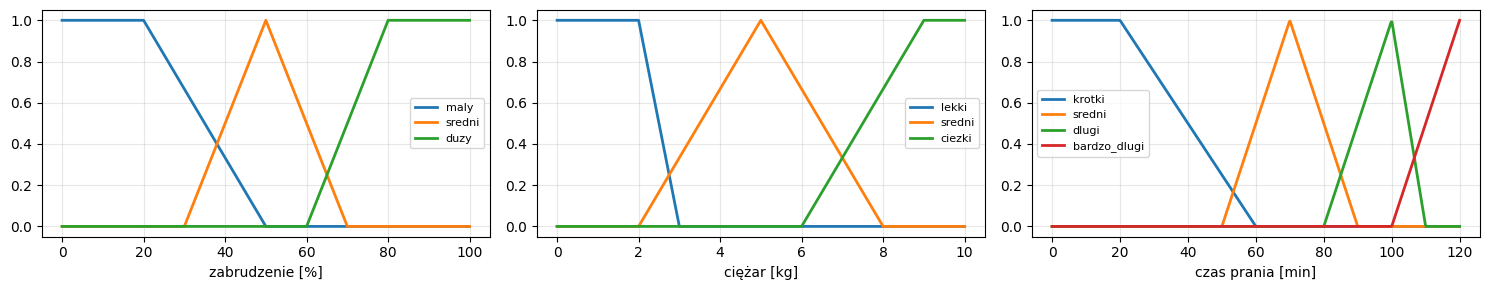

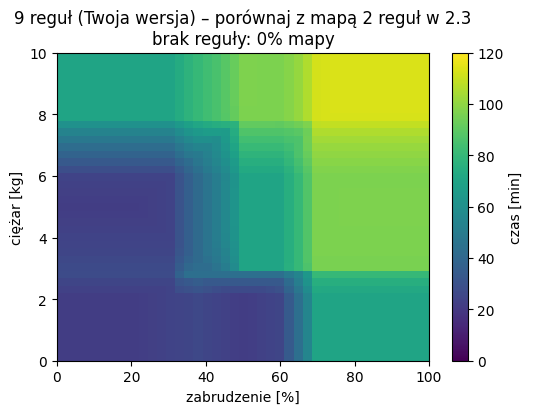

brud 10%, ciężar 1 kg -> 22 min
brud 55%, ciężar 4 kg -> 70 min
brud 90%, ciężar 9 kg -> 113 min


In [37]:
# Uruchamiaj po każdej zmianie
brakuje = [k for k, v in REGULY_9.items() if v is None or k[0] not in BRUD or k[1] not in CIEZAR or v not in CZAS]
if brakuje:
    print("Nie wszystko gotowe – sprawdź te reguły:", brakuje)
else:
    rysuj_zbiory(BRUD, CIEZAR, CZAS)
    Z_9 = mapa(REGULY_9, tytul="9 reguł (Twoja wersja) – porównaj z mapą 2 reguł w 2.3")
    plt.show()
    for b, c in [(10, 1), (55, 4), (90, 9)]:
        print(f"brud {b}%, ciężar {c} kg -> {sterownik(b, c, REGULY_9):.0f} min")

**Pytanie 2d.** Porównaj swoją mapę z mapą osoby obok. Wybierz jeden punkt (np. 70%, 3 kg), dla którego Wasze pralki dają najbardziej różne czasy. Kto ma rację – i jak można by to rozstrzygnąć?

**Pytanie 2e.** 2 wejścia po 3 stany to 9 reguł. Ile reguł trzeba by napisać dla 5 wejść po 3 stany? Co to mówi o ręcznym pisaniu reguł?

*Twoja odpowiedź:*

2d. Mapa osoby obok wskazuje czas około 30 minut dla 30% zabrudzenia i 8kg ciężaru. Moja mapa wskazuje około 70 minut w tym przypadku. Nie ma jednej obiektywnej odpowiedzi, która mapa jest poprawna. Zależy to od ustalonych zbiorów i reguł. W celu znalezienia jak najlepszych reguł powinno się wykonać testy w praktyce.

2e. Dla 5 wejść po 3 stany potrzeba 3^5 = 243 reguł. Liczba reguł rośnie wykładniczo, więc ręczne tworzenie ich jest czasochłonne.

### 2.5 Która decyzja projektowa ma największe znaczenie?

Ten sam sterownik ma trzy „pokrętła”: t-normę w części JEŚLI, implikację i metodę wyostrzania. Porównajmy, jak bardzo każde z nich zmienia całą mapę.

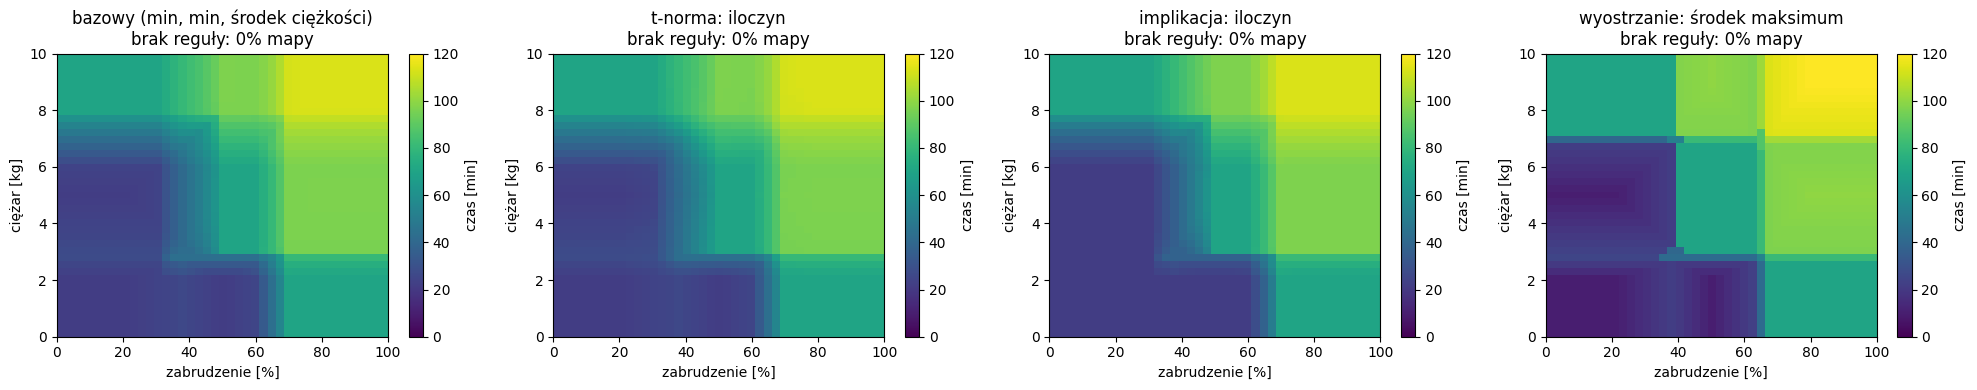

t-norma: iloczyn                 średnia różnica:  0.3 min, największa: 15.3 min
implikacja: iloczyn              średnia różnica:  1.5 min, największa:  6.6 min
wyostrzanie: środek maksimum     średnia różnica:  6.3 min, największa: 38.1 min


In [38]:
warianty = {
    "bazowy (min, min, środek ciężkości)": {},
    "t-norma: iloczyn":                    {"T": T_iloczyn},
    "implikacja: iloczyn":                 {"implikacja": "iloczyn"},
    "wyostrzanie: środek maksimum":        {"wyostrzanie": srodek_maksimum},
}
if brakuje:
    print("Najpierw dokończ 2.4 – ta część używa Twojej pełnej bazy reguł.")
else:
    fig, osie = plt.subplots(1, 4, figsize=(20, 4))
    mapy = {n: mapa(REGULY_9, os_, n, **u) for os_, (n, u) in zip(osie, warianty.items())}
    plt.tight_layout(); plt.show()

    Z0 = mapy["bazowy (min, min, środek ciężkości)"]
    for n, Z in list(mapy.items())[1:]:
        d = np.abs(Z - Z0)
        print(f"{n:<32} średnia różnica: {np.nanmean(d):4.1f} min, największa: {np.nanmax(d):4.1f} min")

**Pytanie 2f.** Które pokrętło najbardziej zmienia sterownik? Która mapa ma wyraźne „schodki” (skoki koloru)?



*Twoja odpowiedź:* Wyostrzanie najbardziej zmienia sterownik ze średnią różnicą równą 6.3 min, a największą równą 38.1 min. Również wyostrzanie ma najbardziej wyraźne skoki koloru, przejścia nie są płynne.

### 2.6 Dla chętnych: trzecie wejście

Dodaj wejście **rodzaj tkaniny** z dwoma stanami: `"delikatna"` i `"zwykla"` (np. skala 0–10). Delikatna tkanina powinna skracać pranie.

1. Ile reguł potrzebuje pełna baza dla 3 wejść (3 × 3 × 2)?

Pełna baza wymaga 3 * 3 * 2 = 18 reguł.

2. Funkcja `sterownik` obsługuje tylko dwa wejścia. Co trzeba w niej zmienić, żeby obsłużyła trzecie?

Funkcja sterownik powinna zostać rozszerzona o trzecie wejście. Musi ona wyznaczać stopień przynależności tego parametru, a następnie uwzględniać go przy obliczaniu siły każdej reguły, np. poprzez kolejne zastosowanie t-normy. Konieczna jest również zmiana kluczy słownika reguł tak, aby zawierały trzy warunki zamiast dwóch.

3. Zaproponuj, jak uniknąć pisania wszystkich reguł (np. jedna reguła „JEŚLI tkanina delikatna, TO czas krótki” zamiast dziewięciu).

Możemy ustawić naszą regułę za pomocą None. Jeśli resztę wartości ustawimy na None, to reguła będzie dotyczyła dowolnych wartości tych kryteriów.

In [41]:
TKANINA = {
    "delikatna": lambda x: L(x, 3, 7),
    "zwykla":    lambda x: gamma(x, 3, 7),
}

def sterownik_t(brud, ciezar, tkanina, reguly, T=T_min):
    st = [{n: float(f(v)) for n, f in zb.items()} for zb, v in ((BRUD, brud), (CIEZAR, ciezar), (TKANINA, tkanina))]
    wynik = np.zeros_like(czas)
    for warunki, wyjscie in reguly.items():
        sila = reduce(T, [s[n] for s, n in zip(st, warunki) if n is not None], 1.0)
        wynik = S_max(wynik, np.minimum(sila, CZAS[wyjscie](czas)))
    return srodek_ciezkosci(czas, wynik)

REGULY_t = {(b, c, "zwykla"): v for (b, c), v in REGULY_9.items()}
REGULY_t[(None, None, "delikatna")] = "krotki"

for tk in [0, 5, 10]:
    print(f"tkanina {tk}: {sterownik_t(55, 4, tk, REGULY_t):.0f} min")

tkanina 0: 22 min
tkanina 5: 42 min
tkanina 10: 70 min


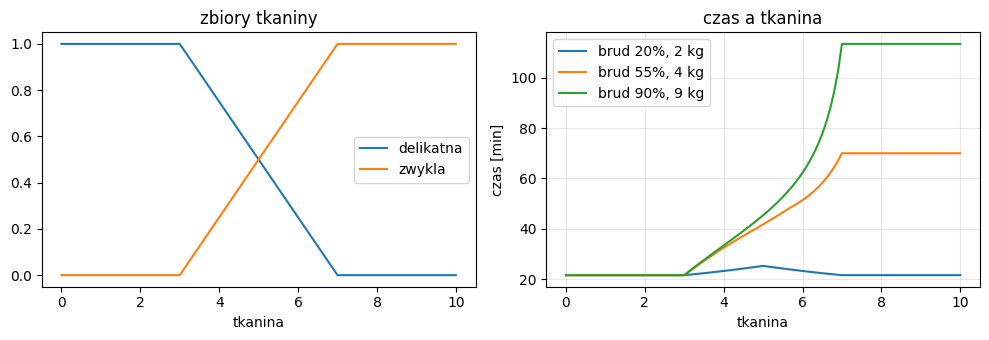

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

xs = np.linspace(0, 10, 201)
for n, f in TKANINA.items():
    ax[0].plot(xs, f(xs), label=n)
ax[0].set_title("zbiory tkaniny"); ax[0].set_xlabel("tkanina"); ax[0].legend()

tk = np.linspace(0, 10, 101)
for b, c in [(20, 2), (55, 4), (90, 9)]:
    ax[1].plot(tk, [sterownik_t(b, c, x, REGULY_t) for x in tk], label=f"brud {b}%, {c} kg")
ax[1].set_title("czas a tkanina"); ax[1].set_xlabel("tkanina"); ax[1].set_ylabel("czas [min]"); ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout(); plt.show()